In [9]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [10]:
%pip install ipynb

Note: you may need to restart the kernel to use updated packages.


In [11]:
import importlib

# Programmatically import the module despite the invalid name
d_c = importlib.import_module("ipynb.fs.full.01_DataCleaning")


In [12]:
d_c.merged_df.head(1)

,account_created_date,personal_spend_baseline_usd,account_type_y,kyc_tier_y,timestamp,day_of_week,hour_of_day,description,merchant_name,merchant_category,...,currency_y,amount_to_avg_ratio,avg_transaction_amount_30d,transaction_velocity_1h,transaction_country,home_country_y,is_cross_border,is_new_device,status,is_fraud
0,8/28/2022,63.23,Individual,Tier3_Enhanced,2/16/2025 14:55,Sunday,14,CNP PURCHASE - BOLT,Bolt,Travel,...,NGN,9.21,9143.33,0,NG,NG,0,0.0,Completed,0


In [14]:
d_c.merged_df.shape

(126000, 22)

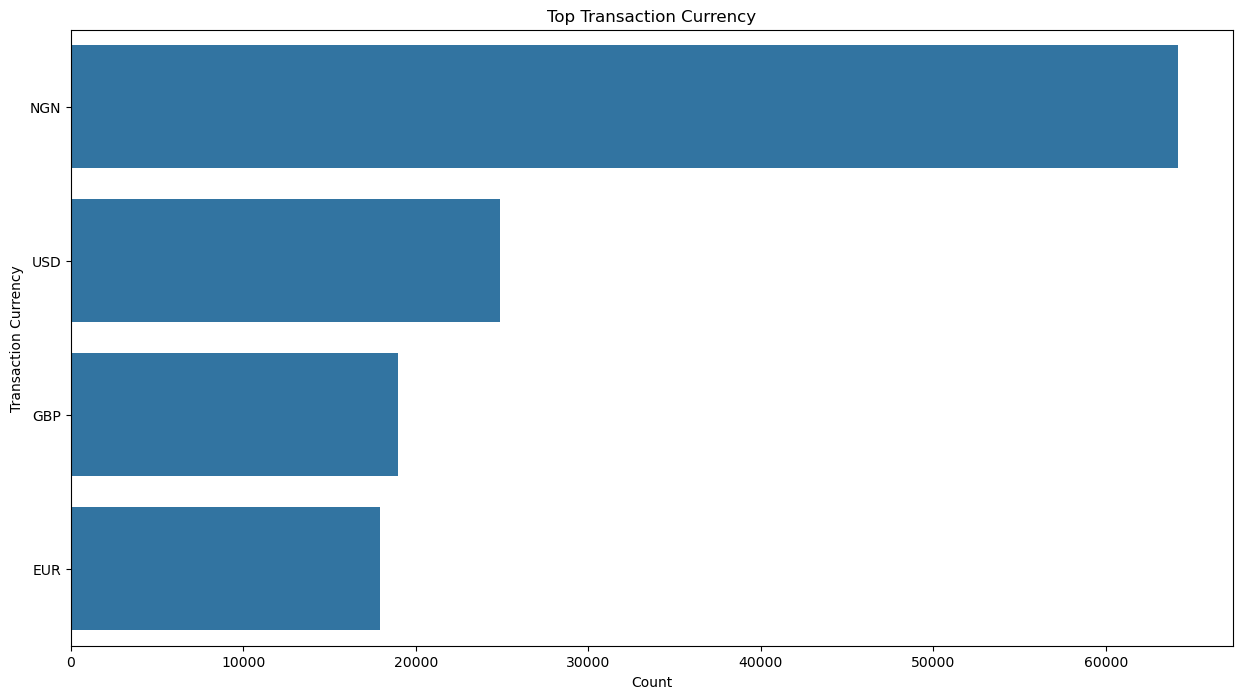

In [15]:
# Transaction Currency
import matplotlib.pyplot as plt
plt.figure(figsize=(15,8))
sns.countplot(y= d_c.merged_df['currency_y'], order= d_c.merged_df['currency_y'].value_counts().index[:4])
plt.title("Top Transaction Currency")
plt.ylabel('Transaction Currency')
plt.xlabel('Count')
plt.show()

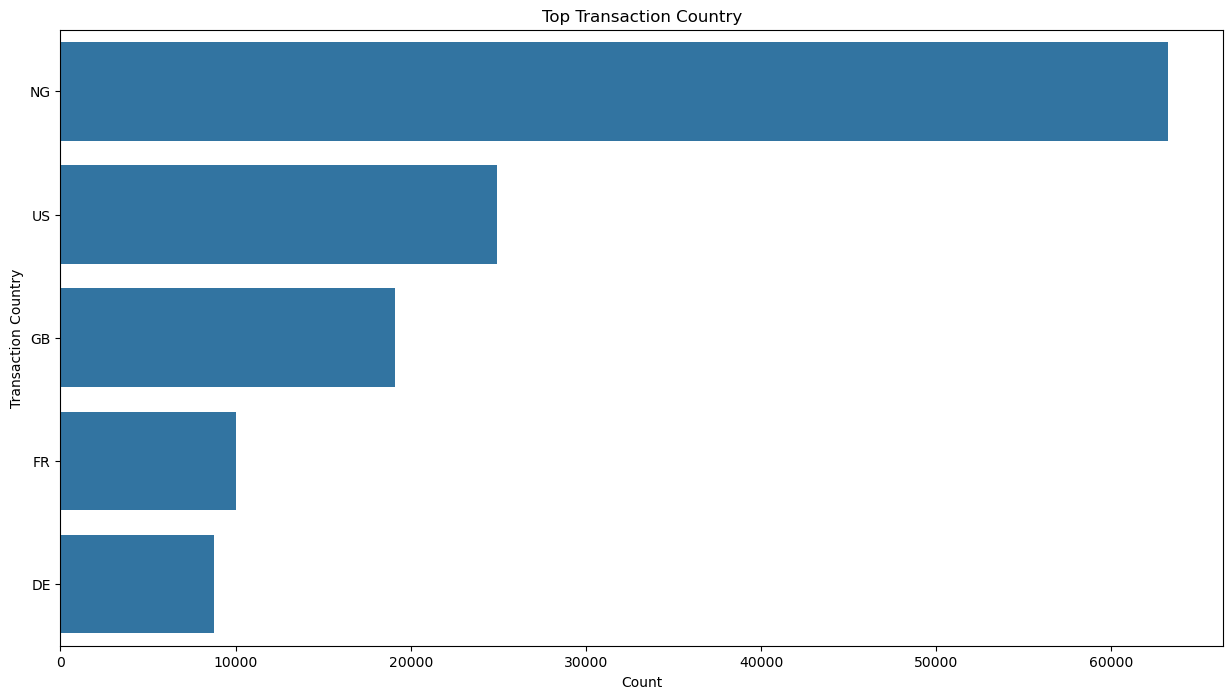

In [17]:
# Transaction Currency
plt.figure(figsize=(15,8))
sns.countplot(y= d_c.merged_df['transaction_country'], order= d_c.merged_df['transaction_country'].value_counts().index[:5])
plt.title("Top Transaction Country")
plt.ylabel('Transaction Country')
plt.xlabel('Count')
plt.show()

In [ ]:
##### The naira was the most commonly transacted currency and most transactions originated from Nigeria.

C:\Users\HP\AppData\Local\Temp\ipykernel_1708\3366867056.py:7: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  fraud_counts = d_c.merged_df.groupby('day_of_week')['is_fraud'].sum().reset_index()
C:\Users\HP\AppData\Local\Temp\ipykernel_1708\3366867056.py:10: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  total_counts = d_c.merged_df.groupby('day_of_week')['is_fraud'].count().reset_index()


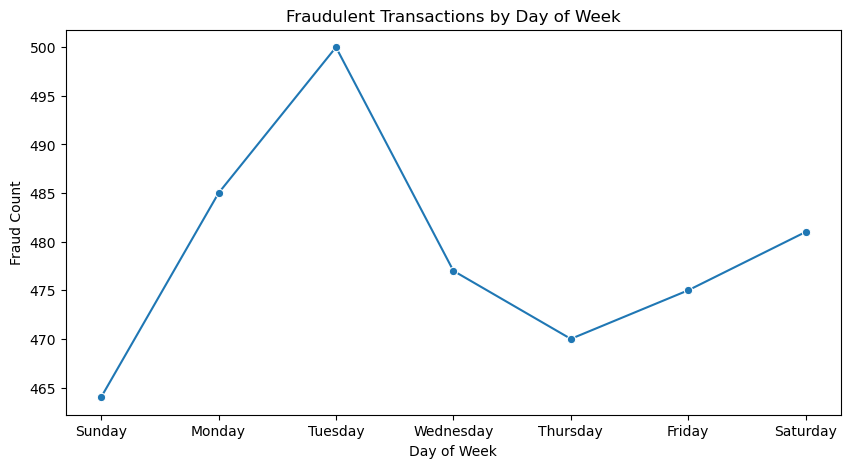

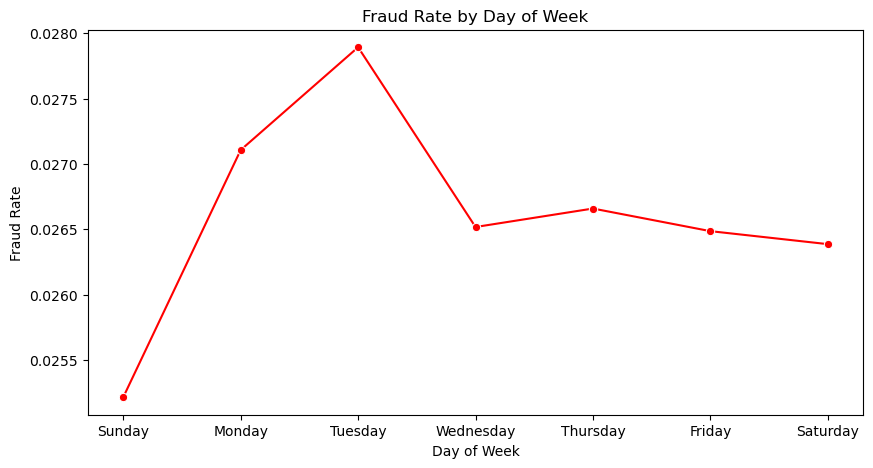

In [19]:
# Weekly Fraud Trend

day_order = ['Sunday','Monday','Tuesday','Wednesday','Thursday','Friday','Saturday']
d_c.merged_df['day_of_week'] = pd.Categorical(d_c.merged_df['day_of_week'], categories=day_order, ordered=True)

# Aggregate fraud counts by day of week
fraud_counts = d_c.merged_df.groupby('day_of_week')['is_fraud'].sum().reset_index()

# Aggregate total transactions by day of week
total_counts = d_c.merged_df.groupby('day_of_week')['is_fraud'].count().reset_index()

# Merge to compute fraud rate
fraud_summary = fraud_counts.merge(total_counts, on='day_of_week', suffixes=('_fraud', '_total'))
fraud_summary['fraud_rate'] = fraud_summary['is_fraud_fraud'] / fraud_summary['is_fraud_total']

# Plot fraud counts
plt.figure(figsize=(10,5))
sns.lineplot(data=fraud_summary, x='day_of_week', y='is_fraud_fraud', marker='o')
plt.title("Fraudulent Transactions by Day of Week")
plt.xlabel("Day of Week")
plt.ylabel("Fraud Count")
plt.show()

# Plot fraud rate
plt.figure(figsize=(10,5))
sns.lineplot(data=fraud_summary, x='day_of_week', y='fraud_rate', marker='o', color='red')
plt.title("Fraud Rate by Day of Week")
plt.xlabel("Day of Week")
plt.ylabel("Fraud Rate")
plt.show()

#### Fraud activities were shown to be highest during the week compared with weekends.

C:\Users\HP\AppData\Local\Temp\ipykernel_1708\3834826028.py:10: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  fraud_counts = d_c.merged_df['is_fraud'].resample('M').sum()
C:\Users\HP\AppData\Local\Temp\ipykernel_1708\3834826028.py:11: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  total_counts = d_c.merged_df['is_fraud'].resample('M').count()


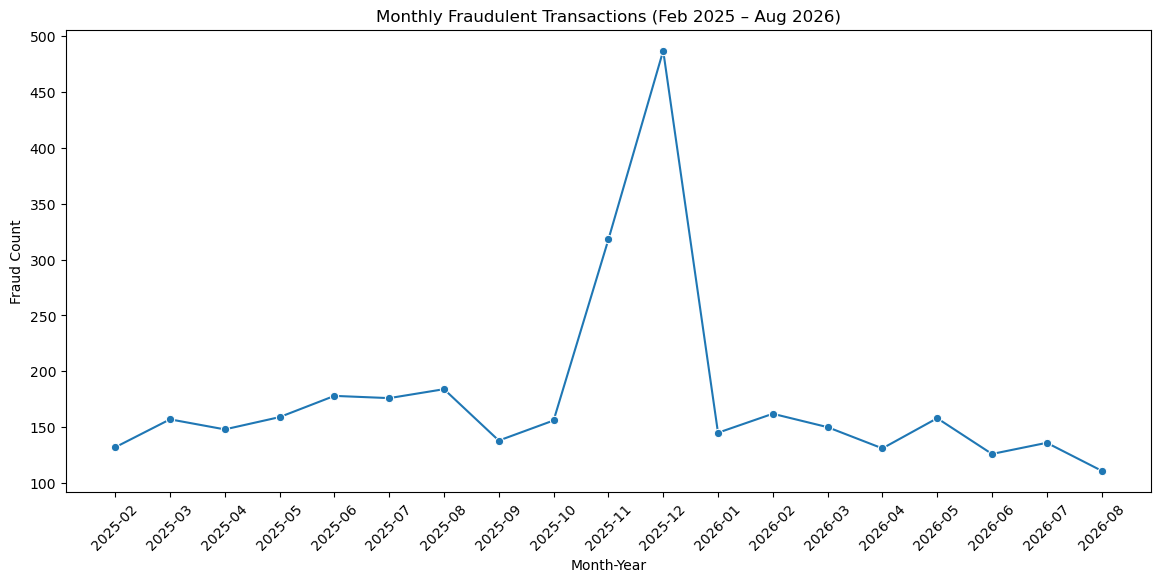

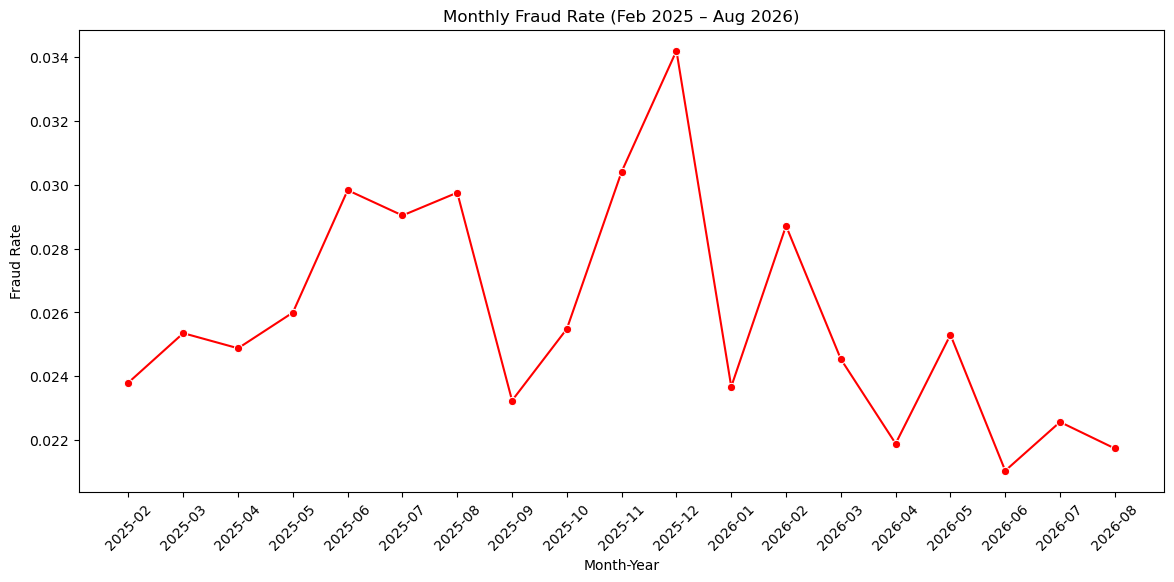

In [20]:
# Monthly Fraud Trend

# Convert timestamp to datetime
d_c.merged_df['timestamp'] = pd.to_datetime(d_c.merged_df['timestamp'])

# Keep timestamp as both column and index
d_c.merged_df = d_c.merged_df.set_index('timestamp', drop=False)

# Resample by month
fraud_counts = d_c.merged_df['is_fraud'].resample('M').sum()
total_counts = d_c.merged_df['is_fraud'].resample('M').count()

# Compute fraud rate
fraud_rate = fraud_counts / total_counts

# Create a summary DataFrame with year-month labels
fraud_summary = pd.DataFrame({
    'year_month': fraud_counts.index.to_period('M').astype(str), 
    'fraud_count': fraud_counts.values,
    'fraud_rate': fraud_rate.values
})

# Plot fraud counts
plt.figure(figsize=(14,6))
sns.lineplot(data=fraud_summary, x='year_month', y='fraud_count', marker='o')
plt.title("Monthly Fraudulent Transactions (Feb 2025 – Aug 2026)")
plt.xlabel("Month-Year")
plt.ylabel("Fraud Count")
plt.xticks(rotation=45)  # rotate labels for readability
plt.show()

# Plot fraud rate
plt.figure(figsize=(14,6))
sns.lineplot(data=fraud_summary, x='year_month', y='fraud_rate', marker='o', color='red')
plt.title("Monthly Fraud Rate (Feb 2025 – Aug 2026)")
plt.xlabel("Month-Year")
plt.ylabel("Fraud Rate")
plt.xticks(rotation=45)
plt.show()


###### There is a noticeable sharp increase in fraud incidence from November 2025 with a peak in January 2026 and a sharp drop in February 2026

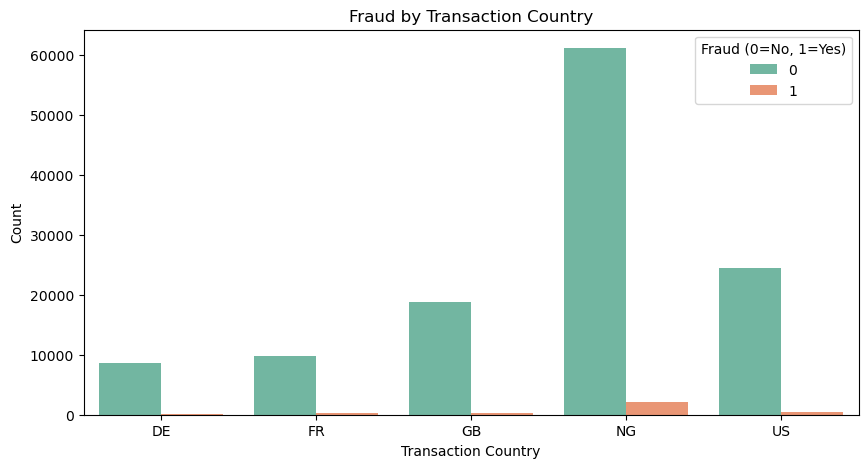

In [21]:
# Transaction country vs fraud
country_summary = d_c.merged_df.groupby(['transaction_country', 'is_fraud']).size().reset_index(name='count')
plt.figure(figsize=(10,5))
sns.barplot(data=country_summary, x='transaction_country', y='count', hue='is_fraud', palette='Set2')
plt.title("Fraud by Transaction Country")
plt.xlabel("Transaction Country")
plt.ylabel("Count")
plt.legend(title="Fraud (0=No, 1=Yes)")
plt.show()

###### Transaction country with the highest fraud rate is Nigeria

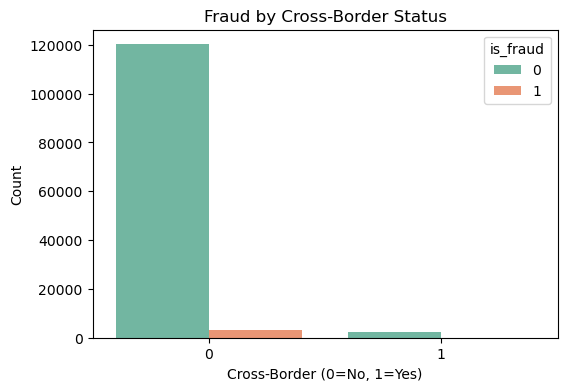

In [22]:
# Cross-border vs fraud
cross_summary = d_c.merged_df.groupby(['is_cross_border', 'is_fraud']).size().reset_index(name='count')
plt.figure(figsize=(6,4))
sns.barplot(data=cross_summary, x='is_cross_border', y='count', hue='is_fraud', palette='Set2')
plt.title("Fraud by Cross-Border Status")
plt.xlabel("Cross-Border (0=No, 1=Yes)")
plt.ylabel("Count")
plt.savefig('Fraud by Cross-Border Status.png')
plt.show()

###### Fraud incidence was noticed to be assosciated with local transactions.

In [23]:
d_c.merged_df.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 126000 entries, 2025-02-16 14:55:00 to 2026-07-26 20:57:00
Data columns (total 22 columns):
 #   Column                       Non-Null Count   Dtype         
---  ------                       --------------   -----         
 0   account_created_date         126000 non-null  object        
 1   personal_spend_baseline_usd  126000 non-null  float64       
 2   account_type_y               126000 non-null  object        
 3   kyc_tier_y                   126000 non-null  object        
 4   timestamp                    126000 non-null  datetime64[ns]
 5   day_of_week                  126000 non-null  category      
 6   hour_of_day                  126000 non-null  int64         
 7   description                  126000 non-null  object        
 8   merchant_name                126000 non-null  object        
 9   merchant_category            126000 non-null  object        
 10  channel                      126000 non-null  object      

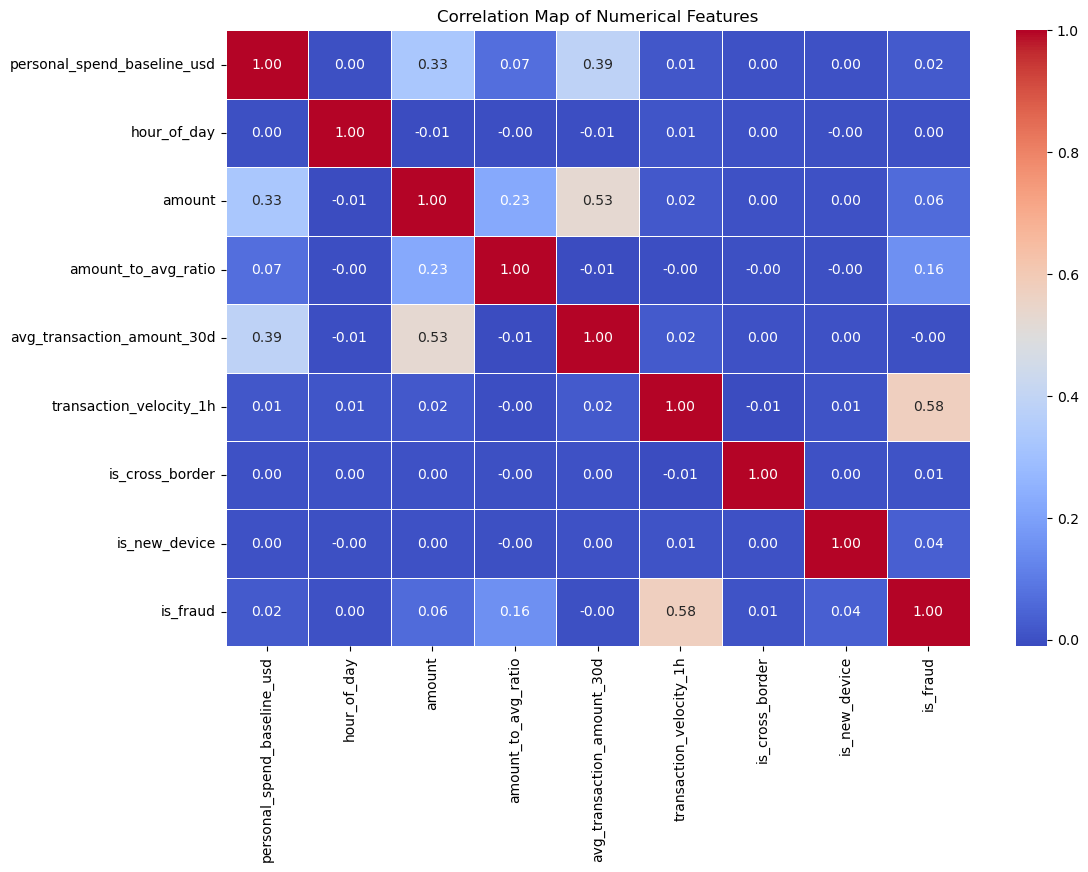

In [24]:
# Select only numeric columns
numeric_df = d_c.merged_df.select_dtypes(include=['int64', 'float64'])

# Compute correlation matrix
corr_matrix = numeric_df.corr()

# Plot correlation heatmap
plt.figure(figsize=(12,8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title("Correlation Map of Numerical Features")
plt.show()


##### Strong Relationships
- Transaction velocity vs fraud
- Correlation = 0.577 → This is the strongest signal. Accounts making multiple transactions in a short time are highly associated with fraud.

##### Amount-to-average ratio vs fraud
- Correlation = 0.155 → Transactions far above or below the user’s average spending are moderately linked to fraud.

##### Transaction amount vs fraud
- Correlation = 0.063 → Larger transaction amounts show a weak but positive association with fraud.

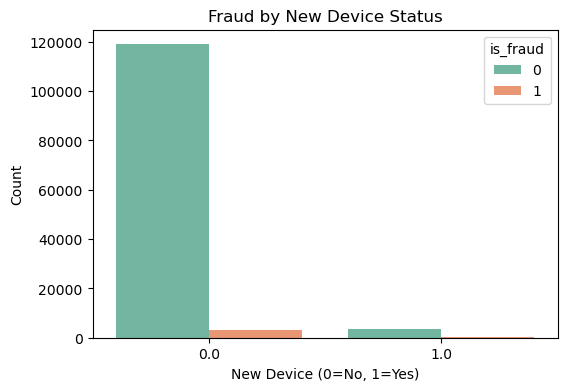

In [27]:
# New device vs fraud

device_summary = d_c.merged_df.groupby(['is_new_device', 'is_fraud']).size().reset_index(name='count')
plt.figure(figsize=(6,4))
sns.barplot(data=device_summary, x='is_new_device', y='count', hue='is_fraud', palette='Set2')
plt.title("Fraud by New Device Status")
plt.xlabel("New Device (0=No, 1=Yes)")
plt.ylabel("Count")
plt.show()

##### Fraud activities were noted more with old devices.

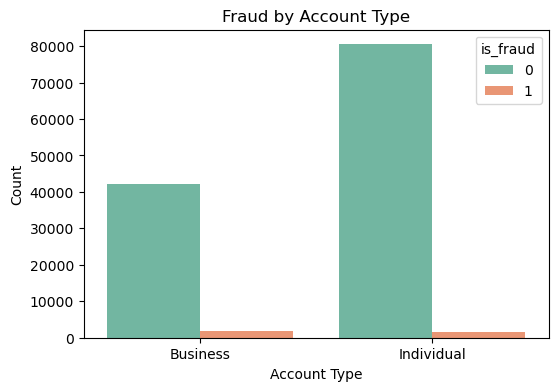

In [28]:
# Account type vs fraud
acct_summary = d_c.merged_df.groupby(['account_type_y', 'is_fraud']).size().reset_index(name='count')
plt.figure(figsize=(6,4))
sns.barplot(data=acct_summary, x='account_type_y', y='count', hue='is_fraud', palette='Set2')
plt.title("Fraud by Account Type")
plt.xlabel("Account Type")
plt.ylabel("Count")
plt.show()


##### Fraudulent activities were more assosciated with business accounts compared with individual accounts.

C:\Users\HP\AppData\Local\Temp\ipykernel_1708\3881543001.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_merchants_cat.values, y=top_merchants_cat.index, palette="Reds_r")


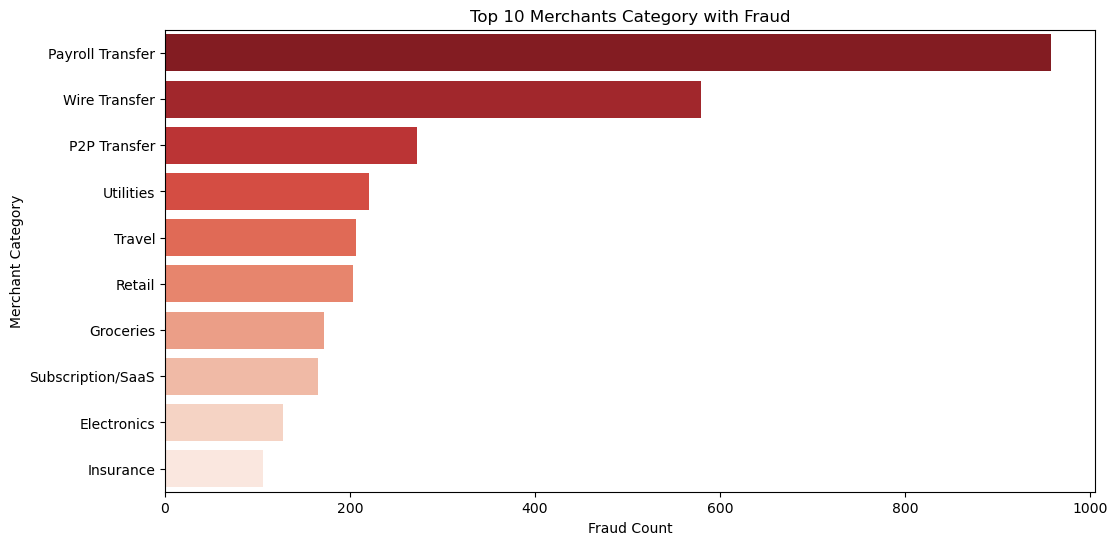

In [31]:
# Top 10 merchant categories associated with fraud
top_merchants_cat = (
    d_c.merged_df[d_c.merged_df['is_fraud'] == 1]   # filter only fraud cases
    .groupby('merchant_category')['is_fraud']   # group by merchant
    .sum()                                  # count frauds per merchant
    .sort_values(ascending=False)           # sort descending
    .head(10)                               # take top 10
)

# print(top_merchants)

plt.figure(figsize=(12,6))
sns.barplot(x=top_merchants_cat.values, y=top_merchants_cat.index, palette="Reds_r")
plt.title("Top 10 Merchants Category with Fraud")
plt.xlabel("Fraud Count")
plt.ylabel("Merchant Category")
plt.show()

###### Merchant category associated with the most fraud is payroll transfer.

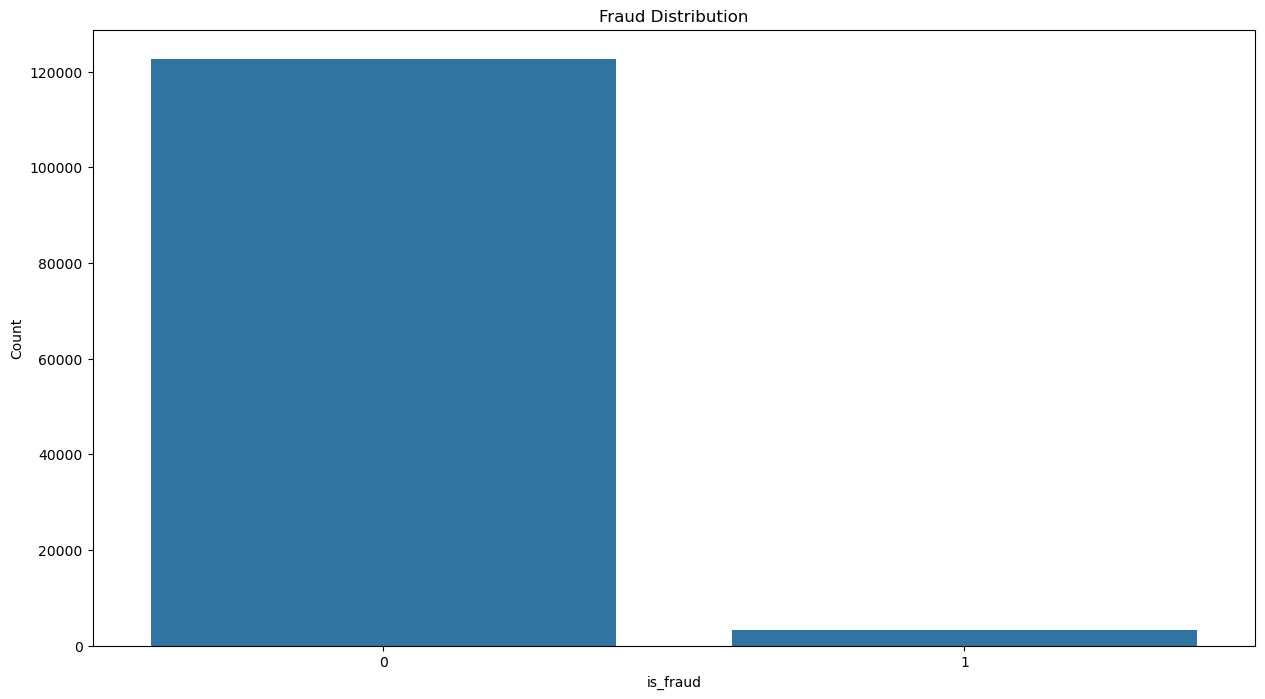

In [30]:
# is_Fraud
plt.figure(figsize=(15,8))
sns.countplot(x= d_c.merged_df['is_fraud'], order= d_c.merged_df['is_fraud'].value_counts().index[:2])
plt.title("Fraud Distribution")
plt.ylabel('Count')
plt.xlabel('is_fraud')
plt.show()

###### There is a clear class imbalance between is_fraud flags with the data showing only a few flagged fraudulent transactions.